In [1]:
import random
import discretisedfield as df
import micromagneticmodel as mm
import oommfc as mc

In [2]:
random.seed(2)

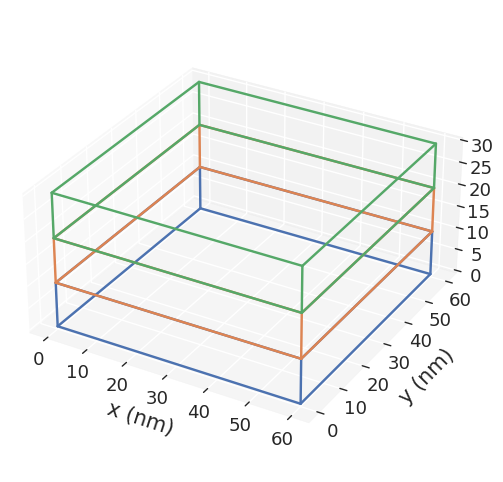

In [3]:
p1 = (0, 0, 0)
p2 = (60e-9, 60e-9, 30e-9)
region = df.Region(p1=p1, p2=p2)
subregions = {
    "r1": df.Region(p1=(0, 0, 0), p2=(60e-9, 60e-9, 10e-9)),
    "r2": df.Region(p1=(0, 0, 10e-9), p2=(60e-9, 60e-9, 20e-9)),
    "r3": df.Region(p1=(0, 0, 20e-9), p2=(60e-9, 60e-9, 30e-9)),
}
mesh = df.Mesh(region=region, n=(20, 20, 9), subregions=subregions)

mesh.mpl.subregions()

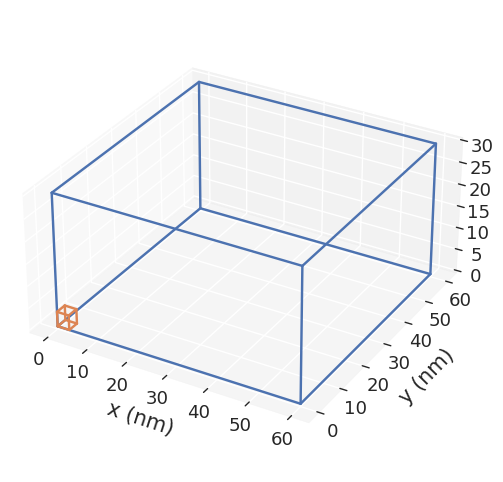

In [5]:
mesh.mpl()

In [21]:
system = mm.System(name="negative_A")

A = 1e-12
Adict = {"r1": A, "r2": A, "r3": A, "r1:r2": -A, "r2:r3": -A}

#system.energy = mm.Exchange(A=Adict) + mm.UniaxialAnisotropy(K=1e4, u=(1, 0, 0))
system.energy = mm.Exchange(A=Adict)

In [22]:
system.energy

Exchange(A={'r1': 1e-12, 'r2': 1e-12, 'r3': 1e-12, 'r1:r2': -1e-12, 'r2:r3': -1e-12})

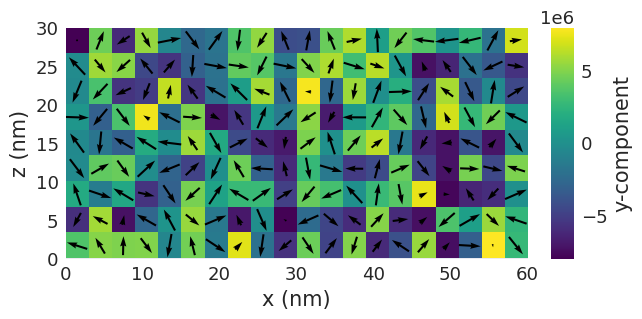

In [23]:
def m_random(point):
    return [2 * random.random() - 1 for i in range(3)]

system.m = df.Field(mesh, nvdim=3, value=m_random, norm=8e6)

system.m.sel("y").mpl(figsize=(12, 3))

Running OOMMF (ExeOOMMFRunner)[2026-10-28T23:59:09]... (0.4 s)


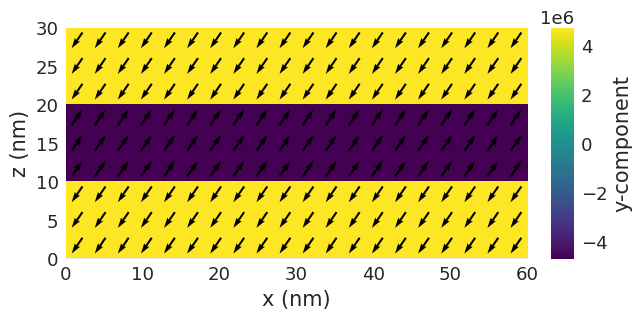

In [24]:
md = mc.MinDriver()
md.drive(system)

system.m.sel("y").mpl(figsize=(12, 3))